# Fast EIGER Correction Extraction: Aggregate Repeated Angles

This notebook retains the existing EIGER calibration model and fitting/validation routines while reducing repeated-angle scans to one summed frame per angle group. The number of exact angles and tolerance groups is reported for the selected scan below.

> **Interpretation:** The default groups angles within 0.001 degrees of each group's lowest angle. Nearby angles are represented by the arithmetic mean of the motor readings, with one equally weighted reading per raw frame and no I0 weighting. This is an approximation; set the tolerance to 0 for exact-only grouping. Raw counts and I0 are summed, with I0 used only for intensity normalization, not geometry. A pixel is excluded from a group if any constituent value is nonfinite, negative, or saturated. Validation splits whole angle groups, so individual repeat anomalies cannot be assessed in this fast path. Group frame gains are diagnostics only, not transferable corrections.

Summation is used rather than a mean because the fitter expects raw counts with Poisson statistics and an I0 exposure normalization. The original source files are not changed. Set `USE_ANGLE_AGGREGATION=False` for the original per-frame path.

In [ ]:
from pathlib import Path
import importlib
import json
import sys
import tempfile
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np

REPO_DIRECTORY = Path.cwd().resolve()
while REPO_DIRECTORY != REPO_DIRECTORY.parent and not (REPO_DIRECTORY / 'eiger_workflow.py').exists():
    REPO_DIRECTORY = REPO_DIRECTORY.parent
if not (REPO_DIRECTORY / 'eiger_workflow.py').exists():
    raise FileNotFoundError('Could not find eiger_workflow.py; launch Jupyter from the repository or a subdirectory.')

DATA_DIRECTORY = Path('/dls/i15-1/data/2026/cm44163-4')
OUTPUT_DIRECTORY = REPO_DIRECTORY / 'outputs'
OUTPUT_DIRECTORY.mkdir(exist_ok=True)
SCAN_PATH = DATA_DIRECTORY / 'i15-1-100585.nxs'
GEOMETRY_PATH = Path('/dls_sw/i15-1/software/daq_configuration/geometry/i15-1-100579_2026-10-15_20-37-08_eiger_goniometer_calibration.json')
CALIBRATION_OUTPUT = OUTPUT_DIRECTORY / f'{SCAN_PATH.stem}_detector_corrections_fast.h5'
TWO_THETA_XY_OUTPUT = OUTPUT_DIRECTORY / f'{SCAN_PATH.stem}_fast_source_effects_2theta.xy'

POLARIZATION_FACTOR = 0.95
SENSOR_DENSITY_G_CM3 = 6.2
FIT_Q_RANGE_NM = (200.0, 400.0)
FIT_BIN_COUNT = 800
# Shared final integration / pre-integration diagnostic bins (independent of fit bins).
THETA_BIN_COUNT = 1000
TWO_THETA_MAX_DEG = None  # Always start at 0; None uses the scan's unmasked pyFAI pixel-centre maximum.
FIT_ITERATIONS = 10
FIT_FRAME_GAINS = True
RUN_VALIDATION = True
WRITE_CALIBRATION = True
WRITE_XY = True
USE_ANGLE_AGGREGATION = True
ANGLE_TOLERANCE_DEG = 0.001
AGGREGATION_METHOD = 'sum'
RAW_SATURATION = 1e7
DETECTOR_PATH = None
MONITOR_PATH = None
METADATA_PATH = None
RUN_UNGROUPED_BENCHMARK = False  # Can be expensive in both time and memory.

if TWO_THETA_MAX_DEG is not None:
    if (not isinstance(TWO_THETA_MAX_DEG, (int, float, np.integer, np.floating))
            or not np.isfinite(TWO_THETA_MAX_DEG) or not 0 < TWO_THETA_MAX_DEG <= 180):
        raise ValueError('TWO_THETA_MAX_DEG must be None or a finite number with 0 < max <= 180 degrees')

assert SCAN_PATH.exists() and GEOMETRY_PATH.exists()
assert not CALIBRATION_OUTPUT.exists(), 'Choose a new CALIBRATION_OUTPUT; existing files are never overwritten.'
if WRITE_XY:
    assert not TWO_THETA_XY_OUTPUT.exists(), 'Choose a new TWO_THETA_XY_OUTPUT; existing files are never overwritten.'
assert AGGREGATION_METHOD == 'sum', 'Raw-count Poisson fitting requires summed counts; mean aggregation is not equivalent.'
assert ANGLE_TOLERANCE_DEG >= 0

print('Repository:', REPO_DIRECTORY)
print('Input scan:', SCAN_PATH)
print('Geometry:', GEOMETRY_PATH)
print('Calibration output:', CALIBRATION_OUTPUT)
print('2theta XY output:', TWO_THETA_XY_OUTPUT if WRITE_XY else 'disabled')
print('Final 2theta bins / lower / upper (degrees):', THETA_BIN_COUNT, 0.0,
      TWO_THETA_MAX_DEG if TWO_THETA_MAX_DEG is not None else 'auto: unmasked pyFAI pixel-centre maximum')
print('Aggregation enabled / method / angle tolerance:', USE_ANGLE_AGGREGATION, AGGREGATION_METHOD, ANGLE_TOLERANCE_DEG)

Repository: /dls/science/users/fer45166/eiger-correction
Input scan: /dls/i15-1/data/2026/cm44163-4/i15-1-100585.nxs
Geometry: /dls_sw/i15-1/software/daq_configuration/geometry/i15-1-100579_2026-10-15_20-37-08_eiger_goniometer_calibration.json
Calibration output: /dls/science/users/fer45166/eiger-correction/outputs/i15-1-100585_detector_corrections_fast.h5
2theta XY output: /dls/science/users/fer45166/eiger-correction/outputs/i15-1-100585_fast_source_effects_2theta.xy
Aggregation enabled / method / angle tolerance: True sum 0.001


## 1–3. Load Inputs, Parse Angle Metadata, and Detect Repeats

Load the NeXus metadata and companion detector/monitor/metadata files through the shared workflow module. The small angle index below avoids loading detector frames into memory just to inspect repetitions.

The figure compares exact-angle repeats with tolerance-group totals, shows every exact angle's offset from its group's minimum against the allowed tolerance, and magnifies the widest-span group. Shaded intervals are **grouping acceptance windows, not measurement uncertainties**: membership requires `angle − group minimum ≤ ANGLE_TOLERANCE_DEG`, not ± tolerance around the mean. The representative angle is the arithmetic mean of all motor readings in the group, independent of I0. If aggregation is disabled, the figure is labelled as a preview only.

Raw scan summary: {'raw frames': 31, 'unique exact angles': 31, 'duplicate frames beyond first': 0, 'maximum repeats at one angle': 1, 'angles repeated more than once': 0}
Angle range (degrees): 0.0 59.999995021299995
Repeat-count distribution (frames per angle -> number of angles): {1: 31}
First source frame -> exact-angle index/repeat count:
0 0.0 0 1
1 5.5483976155 1 1
2 9.0133923198 2 1
3 11.971575848199999 3 1
4 14.6423092626 4 1
5 17.117709781 5 1
6 19.4478869503 6 1
7 21.6638054739 7 1
8 23.786385948899998 8 1
9 25.830722280899998 9 1
10 27.8078019453 10 1
11 29.7262817409 11 1
Tolerance-group preview: 31 exact angles -> 31 groups; maximum span = 0 degrees


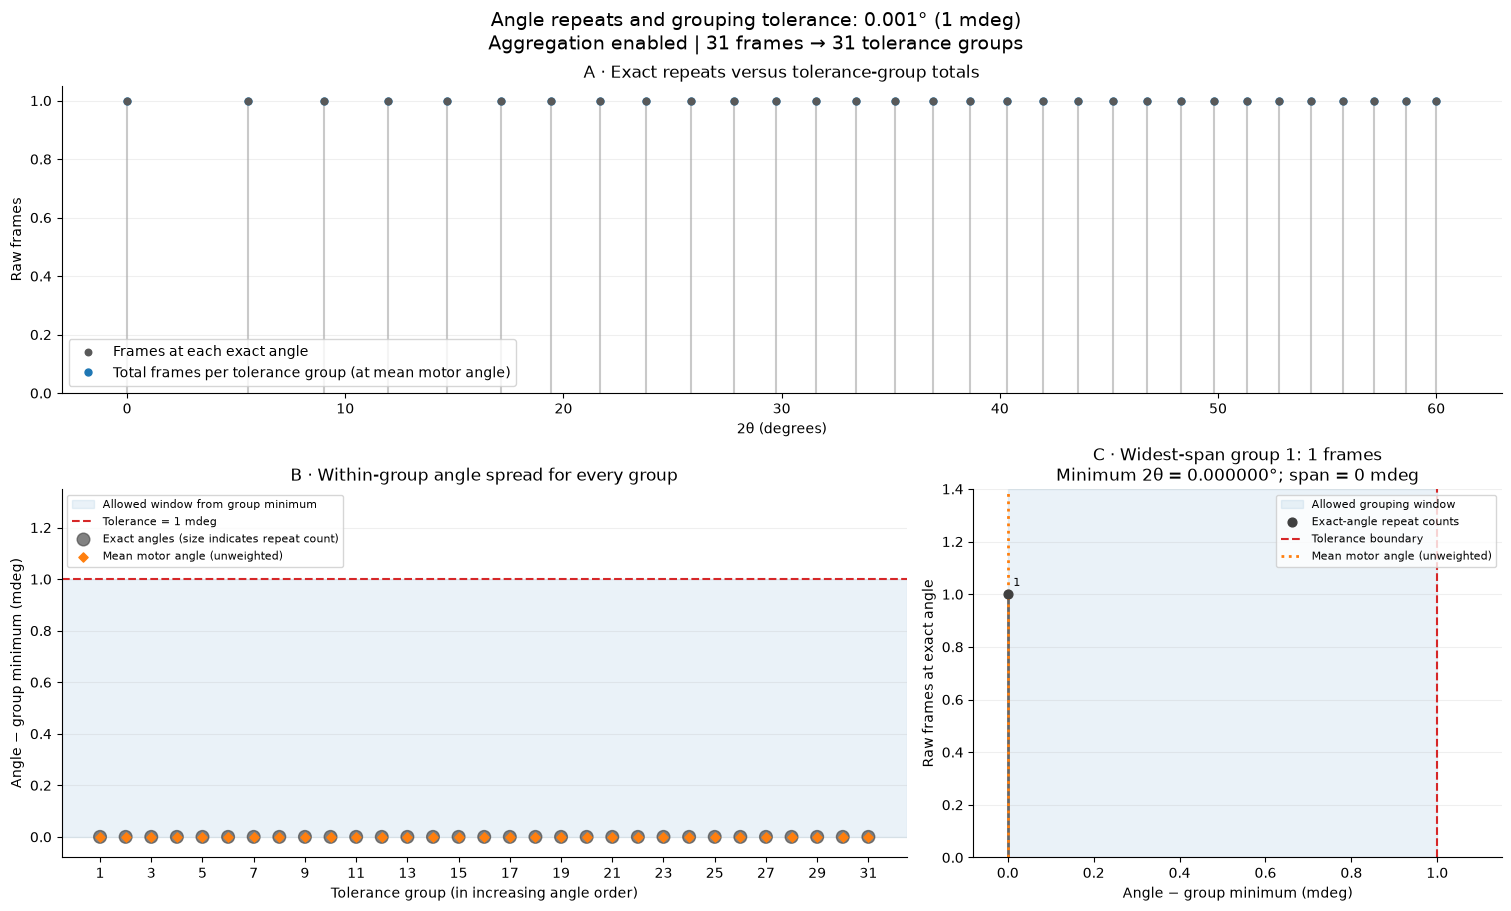

In [28]:
if str(REPO_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(REPO_DIRECTORY))
import eiger_workflow as workflow
importlib.reload(workflow)

raw_scan = workflow.load_scan(SCAN_PATH, DETECTOR_PATH, MONITOR_PATH, METADATA_PATH)
unique_raw_angles, raw_inverse, raw_repeats = np.unique(raw_scan.angles, return_inverse=True, return_counts=True)
repeat_summary = {
    'raw frames': len(raw_scan.angles),
    'unique exact angles': len(unique_raw_angles),
    'duplicate frames beyond first': int(len(raw_scan.angles) - len(unique_raw_angles)),
    'maximum repeats at one angle': int(raw_repeats.max()),
    'angles repeated more than once': int(np.count_nonzero(raw_repeats > 1)),
}
print('Raw scan summary:', repeat_summary)
print('Angle range (degrees):', float(raw_scan.angles.min()), float(raw_scan.angles.max()))
print('Repeat-count distribution (frames per angle -> number of angles):', {
    int(count): int(number) for count, number in zip(*np.unique(raw_repeats, return_counts=True))
})
print('First source frame -> exact-angle index/repeat count:')
for frame_index in range(min(12, len(raw_scan.angles))):
    group_index = int(raw_inverse[frame_index])
    print(frame_index, float(raw_scan.angles[frame_index]), group_index, int(raw_repeats[group_index]))

# Metadata-only preview: use exactly the minimum-anchored rule in
# workflow.aggregate_equal_angle_frames, without reading detector images.
if not np.isfinite(ANGLE_TOLERANCE_DEG) or ANGLE_TOLERANCE_DEG < 0:
    raise ValueError('ANGLE_TOLERANCE_DEG must be finite and nonnegative')
preview_clusters = []
for angle_index, angle in enumerate(unique_raw_angles):
    if not preview_clusters or angle - unique_raw_angles[preview_clusters[-1][0]] > ANGLE_TOLERANCE_DEG:
        preview_clusters.append([angle_index])
    else:
        preview_clusters[-1].append(angle_index)
preview_group_for_angle = np.empty(len(unique_raw_angles), dtype=int)
for group_index, cluster in enumerate(preview_clusters):
    preview_group_for_angle[cluster] = group_index
preview_group_for_frame = preview_group_for_angle[raw_inverse]
preview_counts = np.bincount(preview_group_for_frame)
# Each motor reading contributes equally; I0 does not enter the angle mean.
preview_means = np.array([
    np.mean(raw_scan.angles[preview_group_for_frame == group_index])
    for group_index in range(len(preview_clusters))
])
preview_minima = np.array([unique_raw_angles[cluster[0]] for cluster in preview_clusters])
preview_spreads = np.array([np.ptp(unique_raw_angles[cluster]) for cluster in preview_clusters])
preview_offsets_mdeg = 1000 * (unique_raw_angles - preview_minima[preview_group_for_angle])
tolerance_mdeg = 1000 * ANGLE_TOLERANCE_DEG
preview_numbers = np.arange(1, len(preview_clusters) + 1)
preview_status = 'Aggregation enabled' if USE_ANGLE_AGGREGATION else 'PREVIEW ONLY — aggregation disabled'
print(f'Tolerance-group preview: {len(unique_raw_angles)} exact angles -> {len(preview_clusters)} groups; '
      f'maximum span = {preview_spreads.max():.6g} degrees')

fig = plt.figure(figsize=(15, 9), constrained_layout=True)
grid = fig.add_gridspec(2, 2, height_ratios=(1, 1.2), width_ratios=(1.6, 1))
ax_counts = fig.add_subplot(grid[0, :])
ax_offsets = fig.add_subplot(grid[1, 0])
ax_zoom = fig.add_subplot(grid[1, 1])
fig.suptitle(
    f'Angle repeats and grouping tolerance: {ANGLE_TOLERANCE_DEG:g}° ({tolerance_mdeg:g} mdeg)\n'
    f'{preview_status} | {len(raw_scan.angles):,} frames → {len(preview_clusters)} tolerance groups',
    fontsize=14,
)

ax_counts.vlines(unique_raw_angles, 0, raw_repeats, color='0.65', alpha=0.6)
ax_counts.scatter(unique_raw_angles, raw_repeats, s=22, color='0.35', label='Frames at each exact angle', zorder=3)
ax_counts.plot(preview_means, preview_counts, 'o', color='tab:blue', markersize=5,
               label='Total frames per tolerance group (at mean motor angle)')
ax_counts.set(title='A · Exact repeats versus tolerance-group totals', xlabel='2θ (degrees)', ylabel='Raw frames')
ax_counts.set_ylim(bottom=0)
ax_counts.legend(loc='best')

# Millidegree offsets make the small acceptance windows visible over a wide scan.
for axis in (ax_offsets, ax_zoom):
    if tolerance_mdeg > 0:
        if axis is ax_offsets:
            axis.axhspan(0, tolerance_mdeg, color='tab:blue', alpha=0.09,
                         label='Allowed window from group minimum')
        else:
            axis.axvspan(0, tolerance_mdeg, color='tab:blue', alpha=0.09,
                         label='Allowed grouping window')
ax_offsets.axhline(tolerance_mdeg, color='tab:red', linestyle='--', label=f'Tolerance = {tolerance_mdeg:g} mdeg')
ax_offsets.vlines(preview_numbers, 0, 1000 * preview_spreads, color='0.5', linewidth=1.5)
point_sizes = 18 + 65 * raw_repeats / raw_repeats.max()
ax_offsets.scatter(preview_group_for_angle + 1, preview_offsets_mdeg, s=point_sizes,
                   color='0.3', alpha=0.7, label='Exact angles (size indicates repeat count)', zorder=3)
ax_offsets.scatter(preview_numbers, 1000 * (preview_means - preview_minima), marker='D', s=22,
                   color='tab:orange', label='Mean motor angle (unweighted)', zorder=4)
ax_offsets.set(title='B · Within-group angle spread for every group', xlabel='Tolerance group (in increasing angle order)',
               ylabel='Angle − group minimum (mdeg)')
ax_offsets.set_xticks(preview_numbers[::max(1, len(preview_numbers) // 12)])
offset_scale = max(tolerance_mdeg, float(preview_offsets_mdeg.max()), 0.001)
ax_offsets.set_ylim(-0.08 * offset_scale, 1.35 * offset_scale)
ax_offsets.legend(loc='upper left', fontsize=8)

# Deterministically inspect the widest-span group; still works for exact-only grouping.
zoom_group = int(np.argmax(preview_spreads))
zoom_indices = np.asarray(preview_clusters[zoom_group])
zoom_offsets = preview_offsets_mdeg[zoom_indices]
ax_zoom.vlines(zoom_offsets, 0, raw_repeats[zoom_indices], color='0.4', linewidth=2)
ax_zoom.scatter(zoom_offsets, raw_repeats[zoom_indices], color='0.25', s=40, zorder=3,
                label='Exact-angle repeat counts')
ax_zoom.axvline(tolerance_mdeg, color='tab:red', linestyle='--', label='Tolerance boundary')
ax_zoom.axvline(1000 * (preview_means[zoom_group] - preview_minima[zoom_group]),
                color='tab:orange', linestyle=':', linewidth=2, label='Mean motor angle (unweighted)')
for offset, count in zip(zoom_offsets, raw_repeats[zoom_indices]):
    ax_zoom.annotate(str(int(count)), (offset, count), xytext=(4, 6), textcoords='offset points', fontsize=8)
ax_zoom.set(title=f'C · Widest-span group {zoom_group + 1}: {preview_counts[zoom_group]} frames\n'
                  f'Minimum 2θ = {preview_minima[zoom_group]:.6f}°; span = {1000 * preview_spreads[zoom_group]:.4g} mdeg',
            xlabel='Angle − group minimum (mdeg)', ylabel='Raw frames at exact angle')
ax_zoom.set_xlim(-0.08 * offset_scale, 1.15 * offset_scale)
ax_zoom.set_ylim(0, 1.4 * raw_repeats[zoom_indices].max())
ax_zoom.legend(loc='upper right', fontsize=8)
for axis in (ax_counts, ax_offsets, ax_zoom):
    axis.grid(axis='y', alpha=0.2)
    axis.spines[['top', 'right']].set_visible(False)
plt.show()

## 4–6. Combine Matching Frames and Rebuild the Reduced Processing Dataset

The reusable helper streams frames into a temporary HDF5 dataset, summing counts and I0 per angle group. For every pixel, any invalid member causes that group's pixel to be masked, rather than silently treating missing data as zero. Downstream fitting continues to use the same `Scan`, cache, fitting, and validation interfaces.

In [29]:
aggregation_seconds = 0.0
if USE_ANGLE_AGGREGATION:
    working_directory = tempfile.TemporaryDirectory(dir=OUTPUT_DIRECTORY, prefix='.eiger_fast_')
    AGGREGATED_DATA_PATH = Path(working_directory.name) / 'angle_aggregated_frames.h5'
    aggregation_start = time.perf_counter()
    analysis_scan, frame_groups = workflow.aggregate_equal_angle_frames(
        raw_scan, AGGREGATED_DATA_PATH, saturation=RAW_SATURATION,
        angle_tolerance=ANGLE_TOLERANCE_DEG,
    )
    aggregation_seconds = time.perf_counter() - aggregation_start
else:
    analysis_scan = raw_scan
    frame_groups = [np.array([index], dtype=int) for index in range(len(raw_scan.angles))]
    working_directory = None
    AGGREGATED_DATA_PATH = None

print('Reduced frames:', len(analysis_scan.angles))
print('Frame reduction factor:', len(raw_scan.angles) / len(analysis_scan.angles))
group_angle_spreads = np.array([np.ptp(raw_scan.angles[members]) for members in frame_groups])
print('Groups combining distinct exact angle values:', int(np.count_nonzero(group_angle_spreads > 0)))
print('Maximum source-angle span within a group (degrees):', float(group_angle_spreads.max()))
print('Aggregation elapsed (s):', aggregation_seconds)
print('Reduced detector dataset shape:', (len(analysis_scan.angles), *analysis_scan.shape))
print('I0 aggregation check:', bool(np.all(analysis_scan.i0 > 0)))
if AGGREGATED_DATA_PATH is not None:
    with h5py.File(AGGREGATED_DATA_PATH, 'r') as grouped_file:
        np.testing.assert_equal(grouped_file['data'].shape, (len(frame_groups), *raw_scan.shape))
        np.testing.assert_equal(grouped_file['source_frame_indices'].shape[0], len(raw_scan.angles))
        print('Temporary grouped HDF5:', AGGREGATED_DATA_PATH)

# Check one of the smallest repeated groups without stacking all its raw images.
check_group_index = min(
    (i for i, members in enumerate(frame_groups) if len(members) > 1),
    key=lambda i: len(frame_groups[i]), default=None,
)
if check_group_index is not None and AGGREGATED_DATA_PATH is not None:
    members = frame_groups[check_group_index]
    expected = np.zeros(raw_scan.shape, dtype=float)
    invalid_any = np.zeros(raw_scan.shape, dtype=bool)
    with h5py.File(raw_scan.detector_path, 'r') as raw_file, h5py.File(AGGREGATED_DATA_PATH, 'r') as grouped_file:
        for frame_index in members:
            raw_frame = np.asarray(raw_file[raw_scan.detector_dataset][int(frame_index)], dtype=float)
            invalid = ~np.isfinite(raw_frame) | (raw_frame < 0) | (raw_frame >= RAW_SATURATION)
            invalid_any |= invalid
            expected += np.where(invalid, 0.0, raw_frame)
        expected[invalid_any] = np.nan
        np.testing.assert_allclose(grouped_file['data'][check_group_index], expected, rtol=0, atol=0, equal_nan=True)
        np.testing.assert_allclose(analysis_scan.i0[check_group_index], raw_scan.i0[members].sum(), rtol=1e-14)
    angle_spread = float(np.ptp(raw_scan.angles[members]))
    print('Sample aggregate raw-count and summed-I0 checks passed for', len(members), 'frames; angle spread (degrees):', angle_spread)
else:
    print('No repeated group available for the sample check; dataset shape and I0 checks passed.')

Reduced frames: 31
Frame reduction factor: 1.0
Groups combining distinct exact angle values: 0
Maximum source-angle span within a group (degrees): 0.0
Aggregation elapsed (s): 0.6032794406637549
Reduced detector dataset shape: (31, 512, 1028)
I0 aggregation check: True
Temporary grouped HDF5: /dls/science/users/fer45166/eiger-correction/outputs/.eiger_fast_1omcbv1_/angle_aggregated_frames.h5
No repeated group available for the sample check; dataset shape and I0 checks passed.


In [30]:
geometry_config = json.loads(GEOMETRY_PATH.read_text())
physical_model = workflow.PhysicalModel(geometry_config, analysis_scan, POLARIZATION_FACTOR, SENSOR_DENSITY_G_CM3)
geometry_checks = physical_model.vertical_check()
boundary_mask, sensor_ids = workflow.detector_layout(analysis_scan.shape)
base_mask = analysis_scan.native_mask | boundary_mask
sensor_ids[base_mask] = -1
workflow.constant_pattern_check(physical_model, base_mask, FIT_Q_RANGE_NM, FIT_BIN_COUNT)

fit_settings = {
    'q_range': list(FIT_Q_RANGE_NM), 'npt': FIT_BIN_COUNT, 'iterations': FIT_ITERATIONS,
    'fit_frame_gains': FIT_FRAME_GAINS, 'fractional_floor': 0.003, 'reject_z': 5.0,
    'minimum_observations': 8, 'shrink_weight': 300.0, 'frame_prior_sigma': 0.01,
    'angle_aggregation': {
        'enabled': bool(USE_ANGLE_AGGREGATION), 'method': AGGREGATION_METHOD,
        'angle_tolerance_deg': float(ANGLE_TOLERANCE_DEG),
        'source_frame_count': int(len(raw_scan.angles)),
        'analysis_position_count': int(len(analysis_scan.angles)),
        'group_sizes': [int(len(members)) for members in frame_groups],
    },
}
cache_saturation = np.inf if USE_ANGLE_AGGREGATION else RAW_SATURATION
fit_options = {key: value for key, value in fit_settings.items() if key not in {'q_range', 'angle_aggregation'}}

print('Frames / detector shape used for fitting:', len(analysis_scan.angles), analysis_scan.shape)
print('Angle range:', float(analysis_scan.angles.min()), float(analysis_scan.angles.max()))
print('Aggregated I0 range:', float(analysis_scan.i0.min()), float(analysis_scan.i0.max()))
print('Geometry checks:', geometry_checks)
print('Native / boundary-combined mask:', int(analysis_scan.native_mask.sum()), int(base_mask.sum()))
print('CdTe normal transmission / absorbed fraction:', physical_model.transmission, physical_model.efficiency)
print('Constant-pattern physical-correction check passed.')

Frames / detector shape used for fitting: 31 (512, 1028)
Angle range: 0.0 59.999995021299995
Aggregated I0 range: 0.052163468324971415 0.05301957633925412
Geometry checks: [{'angle_deg': 20, 'vertical_fraction': 0.999997428583921, 'chi_deg': 90.10383780797738}, {'angle_deg': 40, 'vertical_fraction': 0.9999993118660422, 'chi_deg': 90.05370294225928}, {'angle_deg': 60, 'vertical_fraction': 0.999999629778898, 'chi_deg': 90.03938685222737}]
Native / boundary-combined mask: 1057 17323
CdTe normal transmission / absorbed fraction: 0.20769048111688532 0.7923095188831146
Constant-pattern physical-correction check passed.


In [31]:
# Compare separate and summed integrations for a tiny representative sample.
# Prefer a tolerance-merged group that actually contributes in the fitting q range.
tolerance_group_index = None
for i, group in enumerate(frame_groups):
    if np.ptp(raw_scan.angles[group]) <= 0:
        continue
    representative_angle = float(np.mean(raw_scan.angles[group]))
    q_pixels = physical_model.arrays(representative_angle)[1]
    q_support = (~base_mask) & (q_pixels >= FIT_Q_RANGE_NM[0]) & (q_pixels < FIT_Q_RANGE_NM[1])
    if np.count_nonzero(q_support) >= 100:
        tolerance_group_index = i
        break

if USE_ANGLE_AGGREGATION and tolerance_group_index is not None:
    tolerance_members = frame_groups[tolerance_group_index]
    _, first_positions = np.unique(raw_scan.angles[tolerance_members], return_index=True)
    sample_indices = tolerance_members[np.sort(first_positions)]
elif USE_ANGLE_AGGREGATION and check_group_index is not None and len(frame_groups[check_group_index]) <= 4:
    sample_indices = frame_groups[check_group_index]
else:
    sample_indices = np.array([], dtype=int)

if len(sample_indices) > 1:
    with h5py.File(raw_scan.detector_path, 'r') as raw_file:
        raw_sample_frames = [
            np.asarray(raw_file[raw_scan.detector_dataset][int(frame_index)], dtype=float)
            for frame_index in sample_indices
        ]
    raw_sample_stack = np.stack(raw_sample_frames)
    invalid_any = np.any(
        ~np.isfinite(raw_sample_stack) | (raw_sample_stack < 0) | (raw_sample_stack >= RAW_SATURATION),
        axis=0,
    )
    common_mask = base_mask | invalid_any
    sample_counts = np.where(invalid_any, 0.0, raw_sample_stack).sum(axis=0)
    sample_counts[invalid_any] = np.nan
    sample_i0 = float(raw_scan.i0[sample_indices].sum())
    sample_angle = float(np.mean(raw_scan.angles[sample_indices]))
    per_frame_results = {
        int(frame_index): workflow.integrate_frame(
            physical_model, raw_sample_frames[position], raw_scan.angles[int(frame_index)],
            raw_scan.i0[int(frame_index)], common_mask, np.ones(analysis_scan.shape),
            FIT_BIN_COUNT, FIT_Q_RANGE_NM, saturation=RAW_SATURATION,
        )
        for position, frame_index in enumerate(sample_indices)
    }
    summed_result = workflow.integrate_frame(
        physical_model, sample_counts, sample_angle, sample_i0,
        common_mask, np.ones(analysis_scan.shape), FIT_BIN_COUNT, FIT_Q_RANGE_NM,
        saturation=np.inf,
    )
    separate_merged = workflow.merge_results(per_frame_results)
    separate_intensity = separate_merged['intensity']
    valid_bins = (summed_result.count > 0) & (separate_merged['accumulators'][3] > 0)
    valid_bins &= np.isfinite(summed_result.intensity) & np.isfinite(separate_intensity)
    valid_bins &= (summed_result.intensity > 0) & (separate_intensity > 0)
    relative_difference = np.abs(summed_result.intensity[valid_bins] - separate_intensity[valid_bins]) / separate_intensity[valid_bins]
    print('Sample separate-vs-summed integration; frames:', len(sample_indices), 'angle span (deg):', float(np.ptp(raw_scan.angles[sample_indices])))
    if relative_difference.size:
        print('Relative intensity difference, median / 95th percentile / max (%):', 100 * np.percentile(relative_difference, [50, 95, 100]))
    else:
        print('No common supported q bins in the sample integration comparison.')
else:
    print('Integration comparison skipped: no tolerance-merged group contributes in the fitting q range.')

Integration comparison skipped: no tolerance-merged group contributes in the fitting q range.


## Run the Existing Fit and Held-Out Validation on the Reduced Scan

The fitting and integration logic is the same as the original notebook. The alternating-position validation now holds out complete angle groups; group-level frame gains remain source-only diagnostics.

Cache construction time (s): 1.5724006416276097
Cached contributing angle groups: 23
Cached observations: 9182326
Sparse cache memory (MiB): 122.5972785949707

 Even angle groups train / odd test
{'iteration': 1, 'rejected_percent': np.float64(0.0), 'max_log_gain_change': 0.16553770706912954}
{'iteration': 2, 'rejected_percent': np.float64(0.0), 'max_log_gain_change': 0.02290328420666972}
{'iteration': 3, 'rejected_percent': np.float64(0.0038675808687655025), 'max_log_gain_change': 0.1511741813889124}
{'iteration': 4, 'rejected_percent': np.float64(0.0045513520720831604), 'max_log_gain_change': 0.008947470952356654}
{'iteration': 5, 'rejected_percent': np.float64(0.0045513520720831604), 'max_log_gain_change': 0.0005915557129246435}
{'iteration': 6, 'rejected_percent': np.float64(0.0045513520720831604), 'max_log_gain_change': 0.00024992733686746843}
{'iteration': 7, 'rejected_percent': np.float64(0.0045513520720831604), 'max_log_gain_change': 0.00014985203907667117}
{'iteration': 8, 're

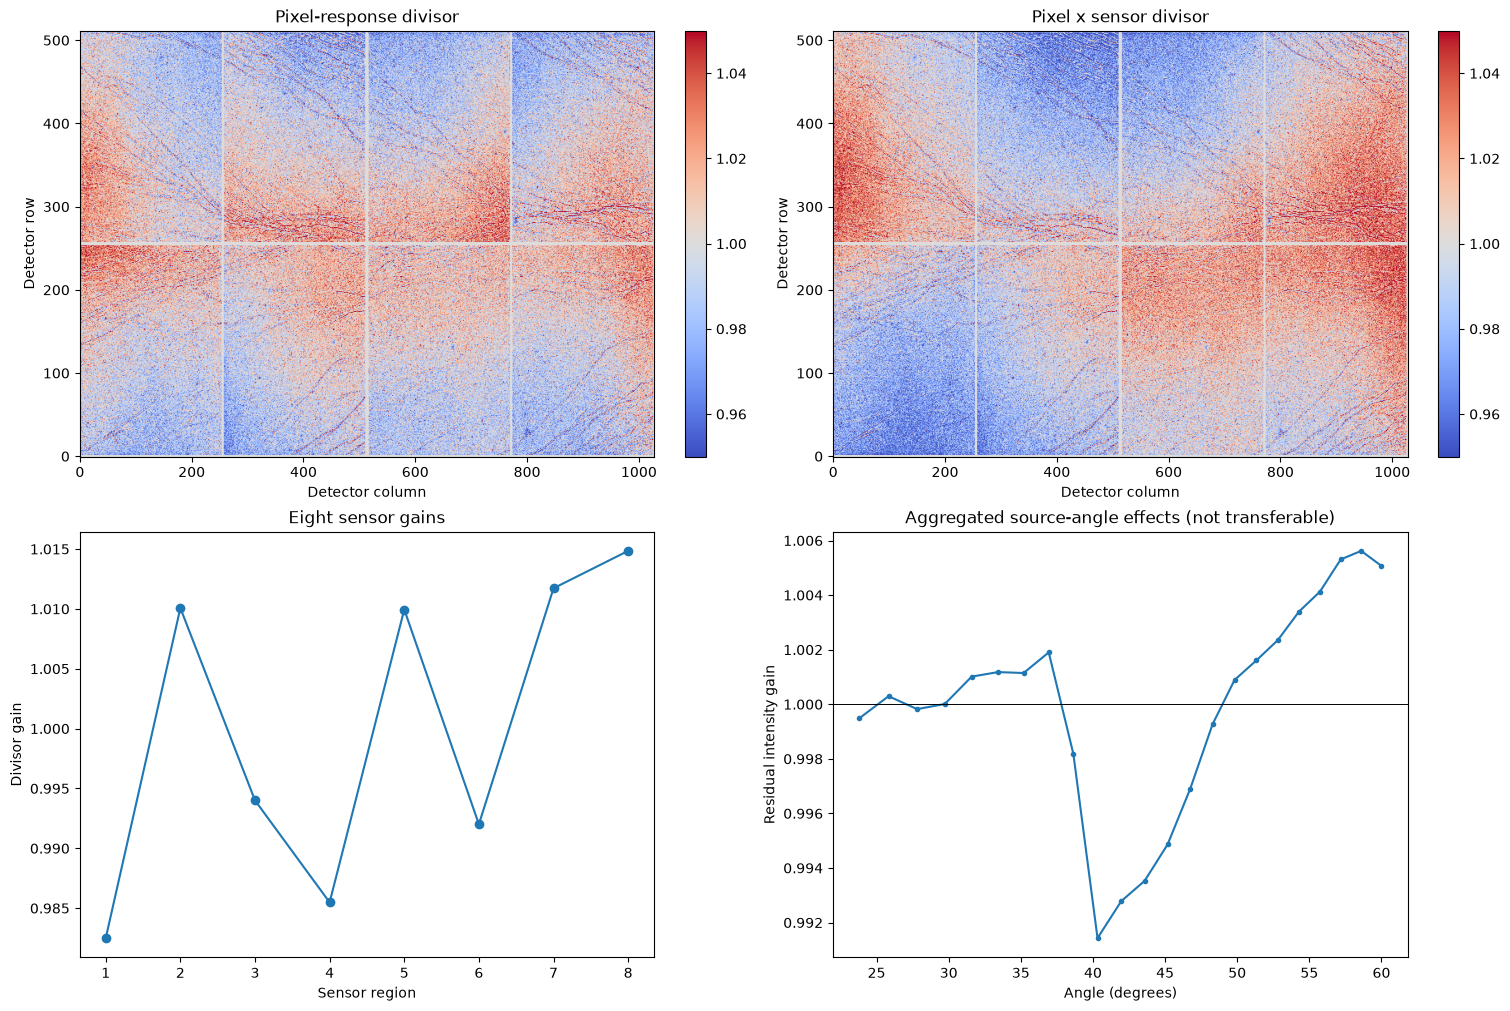

In [32]:
cache_start = time.perf_counter()
cache = workflow.build_cache(
    analysis_scan, physical_model, base_mask, FIT_Q_RANGE_NM, FIT_BIN_COUNT,
    saturation=cache_saturation,
)
cache_seconds = time.perf_counter() - cache_start
contributing_indices = np.array(sorted(cache), dtype=int)
print('Cache construction time (s):', cache_seconds)
print('Cached contributing angle groups:', len(contributing_indices))
print('Cached observations:', sum(len(frame['pixels']) for frame in cache.values()))
cache_bytes = sum(array.nbytes for frame in cache.values() for array in frame.values())
print('Sparse cache memory (MiB):', cache_bytes / 2**20)

validation_reports = []
validation_fits = []
if RUN_VALIDATION:
    folds = (
        ('Even angle groups train / odd test', contributing_indices[contributing_indices % 2 == 0], contributing_indices[contributing_indices % 2 == 1]),
        ('Odd angle groups train / even test', contributing_indices[contributing_indices % 2 == 1], contributing_indices[contributing_indices % 2 == 0]),
    )
    for fold_name, train_indices, test_indices in folds:
        print('\n', fold_name)
        fold_fit = workflow.fit_response(cache, train_indices, sensor_ids, len(analysis_scan.angles), **fit_options)
        validation = workflow.validate_response(
            analysis_scan, physical_model, cache, fold_fit, test_indices,
            base_mask, FIT_Q_RANGE_NM, FIT_BIN_COUNT, saturation=cache_saturation,
        )
        validation_reports.append({'fold': fold_name, 'metrics': validation['summary'], 'frame_gain_checks': validation['frame_rows']})
        validation_fits.append(fold_fit)
        for row in validation['summary']:
            print(row)
    fold_sensor_difference = 100 * np.sqrt(np.mean((np.log(validation_fits[0]['sensor_gains']) - np.log(validation_fits[1]['sensor_gains']))**2))
    print('Sensor log-gain RMS difference between folds (%):', fold_sensor_difference)
else:
    print('WARNING: independent angle-group validation is disabled.')

print('\nFull grouped-scan fit')
calibration_fit = workflow.fit_response(cache, contributing_indices, sensor_ids, len(analysis_scan.angles), **fit_options)
print('Sensor gains:', calibration_fit['sensor_gains'])
print('Persistent bad-pixel candidates:', int(calibration_fit['bad_pixel_mask'].sum()))
print('Largest group-level frame gains:')
for index in sorted(contributing_indices, key=lambda index: abs(np.log(calibration_fit['frame_gains'][index])), reverse=True)[:8]:
    print(f'angle={analysis_scan.angles[index]:.6f}; summed I0={analysis_scan.i0[index]:.8f}; residual gain={calibration_fit["frame_gains"][index]:.6f}')

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
for plot_axis, field, title in ((axes[0, 0], 'pixel_divisor', 'Pixel-response divisor'), (axes[0, 1], 'combined_divisor', 'Pixel x sensor divisor')):
    image = plot_axis.imshow(calibration_fit[field], origin='lower', aspect='auto', cmap='coolwarm', vmin=0.95, vmax=1.05)
    plot_axis.set(title=title, xlabel='Detector column', ylabel='Detector row')
    fig.colorbar(image, ax=plot_axis)
axes[1, 0].plot(np.arange(1, 9), calibration_fit['sensor_gains'], marker='o')
axes[1, 0].set(title='Eight sensor gains', xlabel='Sensor region', ylabel='Divisor gain')
axes[1, 1].plot(analysis_scan.angles[contributing_indices], calibration_fit['frame_gains'][contributing_indices], marker='.')
axes[1, 1].axhline(1, color='black', linewidth=0.7)
axes[1, 1].set(title='Aggregated source-angle effects (not transferable)', xlabel='Angle (degrees)', ylabel='Residual intensity gain')
plt.show()

## Q-dependent sampling on the final 2θ bins, before integration

Both panels use the **same full-range, uniform 2θ bins as the final export**, controlled by `THETA_BIN_COUNT` and `TWO_THETA_MAX_DEG`. The lower edge is always **0°**. Set the maximum to a finite number with **0 < max ≤ 180°**, or leave it as `None` (default) to use the maximum finite, unmasked **pyFAI pixel-centre 2θ over all analysis positions**. The shared `workflow.theta_range_for_scan()` helper uses the full geometry and final fixed mask, without reading detector counts; it does not use pixel corners or the fit range. Edges are mapped nonlinearly to Q in **Å⁻¹** using the geometry wavelength in ångströms; these are not uniform Q bins. The fitting range and fitting bin count remain unchanged.

One observation is one retained detector pixel at one analysis position, assigned once by its pixel-centre 2θ. These counts are **before integration but after the final fixed masks** (base, fitted bad pixels, native detector mask) and the same finite/nonnegative/saturation checks as `integrate_frame`; they are not fractional pyFAI pixel-splitting weights. The fit-only cache cannot describe full-range coverage, so this cell streams the original detector data **read-only**, even if the temporary aggregated file has already been removed. No files are written.

For aggregation, raw frames are summed without stacking; any invalid constituent rejects that group's pixel, matching the aggregation helper. Raw-frame equivalents **multiply** retained observations by group size, using the representative group geometry (an approximation for nearby, unequal motor angles). They neither recover discarded measurements nor imply independent angle coverage. Panels A and B show total observations and position coverage.

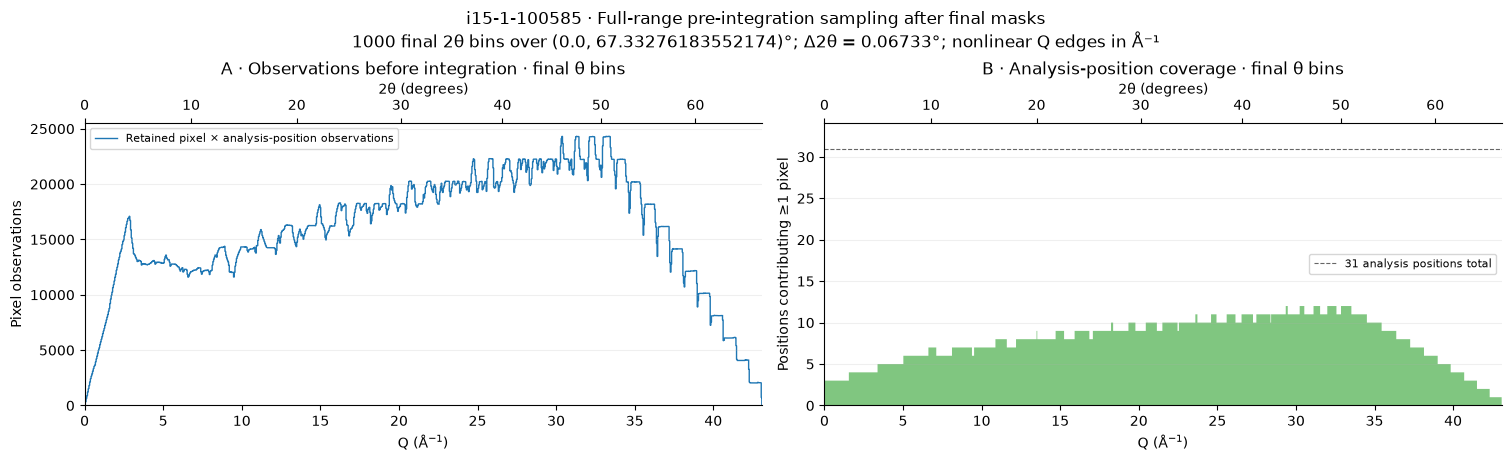

Final 2theta bins / limits (degrees): 1000 (0.0, 67.33276183552174)
Q limits (Å⁻¹): [ 0.         43.08946977]
Source raw frames / analysis positions: 31 31
Total retained pixel observations: 15,778,752
Retained raw-frame equivalents (group geometry approximation): 15,778,752
Bins with no observations: 0 / 1000
Observations per final bin (minimum / median / maximum): 82 16246.0 24315
Contributing positions per final bin (minimum / median / maximum): 1 8.0 12
Observation / raw-equivalent conservation checks passed; elapsed (s): 0.7322123451158404


In [44]:
# Full source reread: final masks and final theta bins, not the fit-only cache.
assert isinstance(THETA_BIN_COUNT, (int, np.integer)) and THETA_BIN_COUNT > 0
q_final_mask = (base_mask.astype(bool) | calibration_fit['bad_pixel_mask'].astype(bool)
                | analysis_scan.native_mask.astype(bool))
q_theta_range_deg = workflow.theta_range_for_scan(
    analysis_scan, physical_model, q_final_mask, theta_max=TWO_THETA_MAX_DEG,
 )
q_theta_edges_deg = np.linspace(*q_theta_range_deg, THETA_BIN_COUNT + 1)
q_wavelength_angstrom = float(physical_model.geometry.wavelength) * 1e10
assert np.isfinite(q_wavelength_angstrom) and q_wavelength_angstrom > 0
q_diagnostic_edges = 4 * np.pi * np.sin(np.deg2rad(q_theta_edges_deg) / 2) / q_wavelength_angstrom
q_diagnostic_centres = 4 * np.pi * np.sin(np.deg2rad(
    0.5 * (q_theta_edges_deg[:-1] + q_theta_edges_deg[1:])) / 2) / q_wavelength_angstrom
q_diagnostic_indices = np.arange(len(analysis_scan.angles), dtype=int)
assert len(frame_groups) == len(q_diagnostic_indices)
q_observations_by_position = np.zeros((len(q_diagnostic_indices), THETA_BIN_COUNT), dtype=np.int64)
q_source_group_sizes = np.array([len(members) for members in frame_groups], dtype=np.int64)
q_expected_observations = 0
q_expected_raw_equivalents = 0
q_statistics_start = time.perf_counter()
with h5py.File(raw_scan.detector_path, 'r') as q_source_file:
    q_source_data = q_source_file[raw_scan.detector_dataset]
    for position, index in enumerate(q_diagnostic_indices):
        q_members = frame_groups[int(index)]
        if USE_ANGLE_AGGREGATION:
            q_counts = np.zeros(analysis_scan.shape, dtype=np.float64)
            q_invalid_any = np.zeros(analysis_scan.shape, dtype=bool)
            for q_frame_index in q_members:
                q_frame = np.asarray(q_source_data[int(q_frame_index)], dtype=np.float64)
                q_invalid = ~np.isfinite(q_frame) | (q_frame < 0) | (q_frame >= RAW_SATURATION)
                q_invalid_any |= q_invalid
                q_counts += np.where(q_invalid, 0.0, q_frame)
            q_counts[q_invalid_any] = np.nan
        else:
            assert len(q_members) == 1
            q_counts = np.asarray(q_source_data[int(q_members[0])], dtype=np.float64)
        # Exactly the integrate_frame count-validity rule, including saturation
        # at infinity for group sums (only constituent saturation is rejected).
        q_bad = q_final_mask | ~np.isfinite(q_counts) | (q_counts < 0) | (q_counts >= cache_saturation)
        q_integrator = physical_model.geometry.get_ai(float(analysis_scan.angles[index]))
        q_theta_pixels_deg = np.rad2deg(q_integrator.center_array(analysis_scan.shape, unit='2th_rad'))
        q_valid = (~q_bad & np.isfinite(q_theta_pixels_deg)
                   & (q_theta_pixels_deg >= q_theta_edges_deg[0])
                   & (q_theta_pixels_deg <= q_theta_edges_deg[-1]))
        q_retained_theta = q_theta_pixels_deg[q_valid]
        q_observations_by_position[position] = np.histogram(q_retained_theta, bins=q_theta_edges_deg)[0]
        q_retained_number = int(np.count_nonzero(q_valid))
        q_expected_observations += q_retained_number
        q_expected_raw_equivalents += q_retained_number * len(q_members)
        assert int(q_observations_by_position[position].sum()) == q_retained_number
q_observation_counts = q_observations_by_position.sum(axis=0)
q_raw_frame_equivalents = q_source_group_sizes @ q_observations_by_position
q_position_coverage = np.count_nonzero(q_observations_by_position, axis=0)
assert int(q_observation_counts.sum()) == q_expected_observations
assert int(q_raw_frame_equivalents.sum()) == q_expected_raw_equivalents
assert np.all(q_raw_frame_equivalents >= q_observation_counts)
assert np.all(q_position_coverage <= len(q_diagnostic_indices))


def Q_to_tth(Q):
    # Clip for Matplotlib's limit evaluation outside the physical Q domain.
    return 2 * np.rad2deg(np.arcsin(np.clip(Q * q_wavelength_angstrom / (4 * np.pi), -1, 1)))


def tth_to_Q(tth):
    return 4 * np.pi * np.sin(np.deg2rad(tth) / 2) / q_wavelength_angstrom


fig_q_statistics = plt.figure(figsize=(15, 4.5), constrained_layout=True)
q_statistics_grid = fig_q_statistics.add_gridspec(1, 2)
q_count_axis = fig_q_statistics.add_subplot(q_statistics_grid[0, 0])
q_coverage_axis = fig_q_statistics.add_subplot(q_statistics_grid[0, 1])
q_statistics_axes = (q_count_axis, q_coverage_axis)
q_count_axis.stairs(q_observation_counts, q_diagnostic_edges, color='tab:blue',
                    label='Retained pixel × analysis-position observations')
if np.any(q_source_group_sizes > 1):
    q_count_axis.stairs(q_raw_frame_equivalents, q_diagnostic_edges, color='tab:orange',
                        label='Retained raw-frame equivalents (approx. group geometry)')
    q_count_axis.set_yscale('symlog', linthresh=1)
q_count_axis.set(title='A · Observations before integration · final θ bins', ylabel='Pixel observations')
q_count_axis.legend(fontsize=8)
q_coverage_axis.stairs(q_position_coverage, q_diagnostic_edges, color='tab:green', fill=True, alpha=0.6)
q_coverage_axis.set(title='B · Analysis-position coverage · final θ bins', ylabel='Positions contributing ≥1 pixel',
                     ylim=(0, max(1, len(q_diagnostic_indices)) * 1.1))
q_coverage_axis.axhline(len(q_diagnostic_indices), color='0.4', linestyle='--', linewidth=0.8,
                        label=f'{len(q_diagnostic_indices)} analysis positions total')
q_coverage_axis.legend(fontsize=8)
for q_axis in q_statistics_axes:
    q_axis.set(xlabel=r'Q ($\mathrm{\AA}^{-1}$)', xlim=(q_diagnostic_edges[0], q_diagnostic_edges[-1]))
    q_axis.spines[['top', 'right']].set_visible(False)
    q_axis.secondary_xaxis('top', functions=(Q_to_tth, tth_to_Q)).set_xlabel('2θ (degrees)')
    q_axis.grid(axis='y', alpha=0.2)
fig_q_statistics.suptitle(
    f'{SCAN_PATH.stem} · Full-range pre-integration sampling after final masks\n'
    f'{THETA_BIN_COUNT} final 2θ bins over {q_theta_range_deg}°; '
    f'Δ2θ = {q_theta_edges_deg[1] - q_theta_edges_deg[0]:.4g}°; nonlinear Q edges in Å⁻¹',
)
plt.show()
print('Final 2theta bins / limits (degrees):', THETA_BIN_COUNT, q_theta_range_deg)
print('Q limits (Å⁻¹):', q_diagnostic_edges[[0, -1]])
print('Source raw frames / analysis positions:', len(raw_scan.angles), len(q_diagnostic_indices))
print('Total retained pixel observations:', f'{q_observation_counts.sum():,}')
print('Retained raw-frame equivalents (group geometry approximation):', f'{q_raw_frame_equivalents.sum():,}')
print('Bins with no observations:', int(np.count_nonzero(q_observation_counts == 0)), '/', THETA_BIN_COUNT)
print('Observations per final bin (minimum / median / maximum):',
      int(q_observation_counts.min()), float(np.median(q_observation_counts)), int(q_observation_counts.max()))
print('Contributing positions per final bin (minimum / median / maximum):',
      int(q_position_coverage.min()), float(np.median(q_position_coverage)), int(q_position_coverage.max()))
print('Observation / raw-equivalent conservation checks passed; elapsed (s):',
      time.perf_counter() - q_statistics_start)

## 7. Benchmark Runtime and Memory

The reduced-path timing includes raw-frame aggregation plus cache construction. The ungrouped benchmark is opt-in because caching every raw frame can require substantial memory; when enabled it measures the same cache-building stage with the original scan and reports observed speedup and sparse-cache bytes.

In [33]:
reduced_path_seconds = aggregation_seconds + cache_seconds
reduced_cache_mib = cache_bytes / 2**20
print('Reduced-path elapsed (aggregation + cache, s):', reduced_path_seconds)
print('Reduced-path sparse cache (MiB):', reduced_cache_mib)
print('Input-to-fit-position reduction:', f'{len(raw_scan.angles)} -> {len(analysis_scan.angles)}', f'({100 * (1 - len(analysis_scan.angles) / len(raw_scan.angles)):.1f}% fewer positions)')

if RUN_UNGROUPED_BENCHMARK:
    import gc
    baseline_start = time.perf_counter()
    baseline_cache = workflow.build_cache(
        raw_scan, physical_model, base_mask, FIT_Q_RANGE_NM, FIT_BIN_COUNT,
        saturation=RAW_SATURATION,
    )
    baseline_seconds = time.perf_counter() - baseline_start
    baseline_bytes = sum(array.nbytes for frame in baseline_cache.values() for array in frame.values())
    print('Ungrouped cache elapsed (s):', baseline_seconds)
    print('Ungrouped sparse cache (MiB):', baseline_bytes / 2**20)
    print('Measured end-to-end cache-path speedup:', baseline_seconds / reduced_path_seconds if reduced_path_seconds else np.nan)
    del baseline_cache
    gc.collect()
else:
    print('Ungrouped timing skipped. Set RUN_UNGROUPED_BENCHMARK=True to measure it; this can use considerably more RAM.')

print('Cache sizes can differ because aggregation intentionally makes each angle group one observation; individual-repeat outlier diagnostics are not retained.')

Reduced-path elapsed (aggregation + cache, s): 2.1756800822913647
Reduced-path sparse cache (MiB): 122.5972785949707
Input-to-fit-position reduction: 31 -> 31 (0.0% fewer positions)
Ungrouped timing skipped. Set RUN_UNGROUPED_BENCHMARK=True to measure it; this can use considerably more RAM.
Cache sizes can differ because aggregation intentionally makes each angle group one observation; individual-repeat outlier diagnostics are not retained.


## 8–9. Save the Calibration, Export a Source XY, and Reuse the Fast Path

The fast path is implemented as `workflow.aggregate_equal_angle_frames()` and is controlled by the aggregation and fallback settings above. After fitting, the notebook also runs the processing integrator on the aggregated source scan and exports a 2theta `.xy` file. For this same source scan only, it explicitly applies the fitted group-level source-angle gains as a best-effort normalization; these gains must not be used on another scan. Full-range 2theta integration extends beyond the fitting q range and should be treated as extrapolation. The temporary aggregated detector file is removed after export; raw source files and the original extraction notebook remain unchanged.

In [ ]:
calibration_file_written = None
try:
    if WRITE_CALIBRATION:
        calibration_file_written = workflow.save_calibration(
            CALIBRATION_OUTPUT, analysis_scan, physical_model, calibration_fit, base_mask,
            sensor_ids, fit_settings, validation_reports,
        )
        saved = workflow.load_calibration(calibration_file_written)
        np.testing.assert_array_equal(saved['combined_divisor'], calibration_fit['combined_divisor'])
        print('Created and read-back verified calibration:', calibration_file_written)
    else:
        saved = {
            'fit_settings': fit_settings,
            'source_scan': str(analysis_scan.path),
            'frame_angles': analysis_scan.angles,
            'frame_i0': analysis_scan.i0,
            'frame_gains': calibration_fit['frame_gains'],
            'combined_divisor': calibration_fit['combined_divisor'],
            'base_mask': base_mask,
            'bad_pixel_mask': calibration_fit['bad_pixel_mask'],
        }
        print('Calibration export disabled; using in-memory fit for source integration.')

    if WRITE_XY:
        processed_for_xy = workflow.process_scan(
            analysis_scan, saved, physical_model,
            q_range=FIT_Q_RANGE_NM, q_npt=FIT_BIN_COUNT, theta_npt=THETA_BIN_COUNT,
            apply_calibration_frame_gains=True,
            allow_extrapolation=True,
            saturation=cache_saturation,
            theta_range=None if TWO_THETA_MAX_DEG is None else (0.0, TWO_THETA_MAX_DEG),
        )
        np.testing.assert_array_equal(processed_for_xy['frame_gains'], calibration_fit['frame_gains'])
        theta_group = processed_for_xy['groups']['merged_2theta']
        supported = (theta_group['accumulators'][1] > 0)
        supported &= np.isfinite(theta_group['axis']) & np.isfinite(theta_group['intensity'])
        xy_data = np.column_stack((theta_group['axis'][supported], theta_group['intensity'][supported]))
        assert xy_data.size > 0, 'No supported 2theta bins are available to export.'
        with TWO_THETA_XY_OUTPUT.open('x', encoding='ascii') as xy_file:
            np.savetxt(xy_file, xy_data, fmt='%.10g', header='2theta_deg intensity')
        print('Created best-effort source-scan 2theta XY:', TWO_THETA_XY_OUTPUT)
        print('Applied fitted group-level source-angle gains:', len(processed_for_xy['frame_gains']))
        print('Exported supported bins:', len(xy_data))
        print('Full-range 2theta bins outside the detector-fit q range are extrapolated.')
    else:
        print('XY export disabled.')
finally:
    if working_directory is not None:
        working_directory.cleanup()
        print('Removed temporary aggregated detector data.')

Created and read-back verified calibration: /dls/science/users/fer45166/eiger-correction/outputs/i15-1-100585_detector_corrections_fast.h5


Created best-effort source-scan 2theta XY: /dls/science/users/fer45166/eiger-correction/outputs/i15-1-100585_fast_source_effects_2theta.xy
Applied fitted group-level source-angle gains: 31
Exported supported bins: 1000
Full-range 2theta bins outside the detector-fit q range are extrapolated.
Removed temporary aggregated detector data.


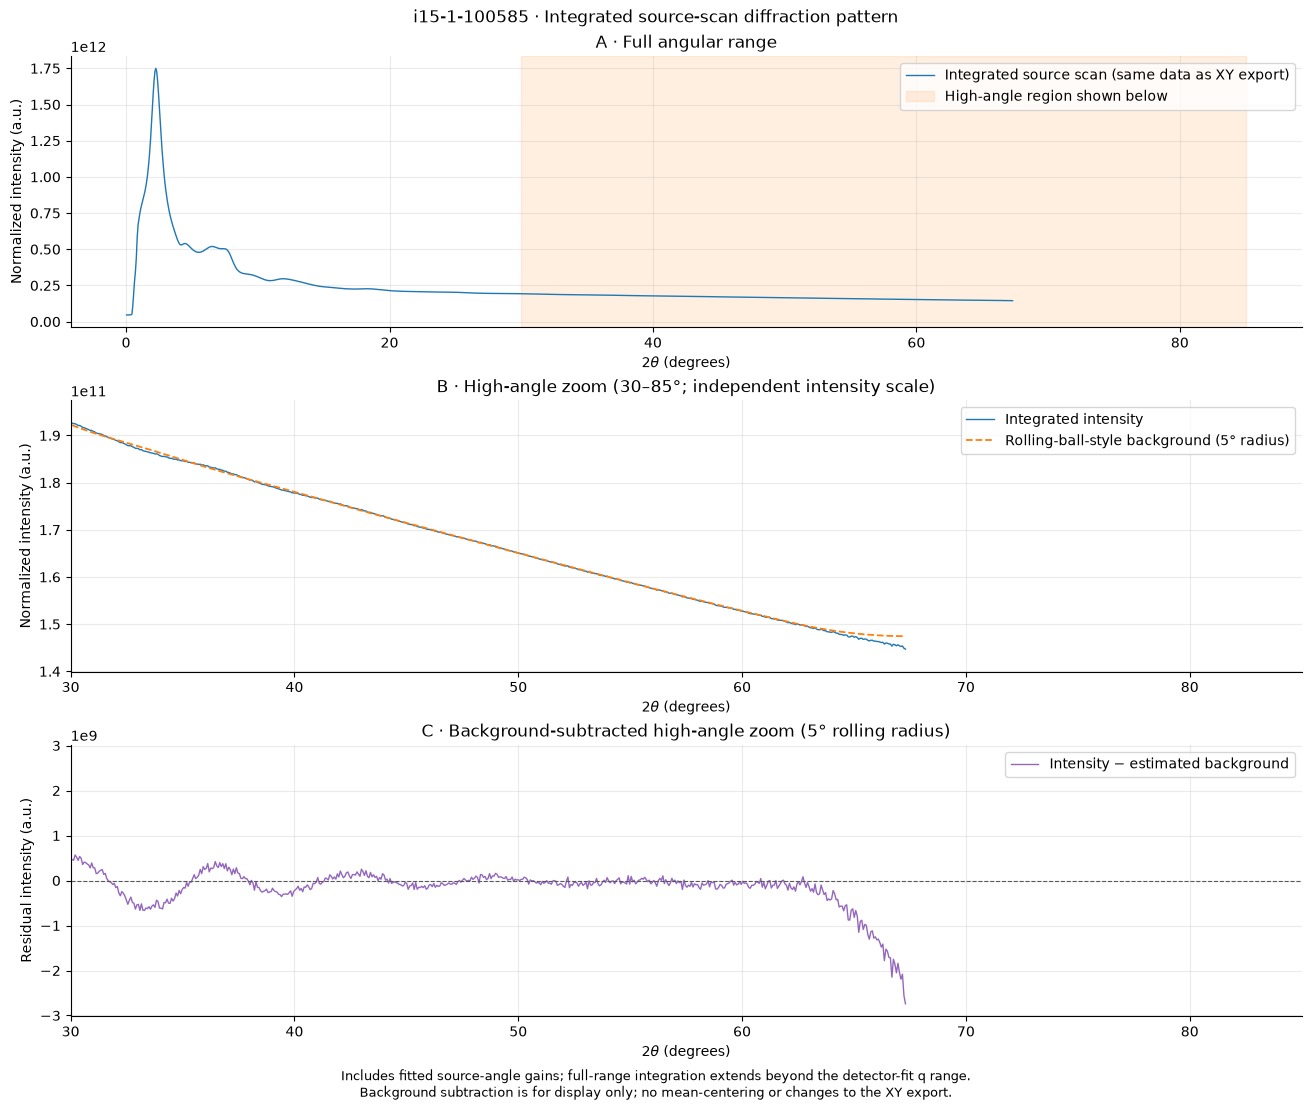

In [35]:
# Plot the exported pattern and a visualization-only background-subtracted view.
# The original integrated intensities and XY export are not modified.
from scipy.ndimage import grey_opening, uniform_filter1d

HIGH_ANGLE_ZOOM_DEG = (30.0, 85.0)
ROLLING_BALL_RADIUS_DEG = 5.0  # Half-width: the full rolling window spans about 10 degrees.

if WRITE_XY:
    if not np.isfinite(ROLLING_BALL_RADIUS_DEG) or ROLLING_BALL_RADIUS_DEG <= 0:
        raise ValueError('ROLLING_BALL_RADIUS_DEG must be finite and positive')
    xy_angles, xy_intensity = xy_data.T
    if len(xy_angles) < 3 or not np.all(np.diff(xy_angles) > 0):
        raise ValueError('Background estimation requires at least three increasing angle bins')

    # Standard 1D rolling-ball-style baseline: morphological opening (minimum
    # then maximum filter), followed by moving-average smoothing. This is not
    # a literal spherical kernel, which would also require an intensity scale.
    # Work on the full pattern before cropping to avoid artificial zoom edges.
    # A uniform grid keeps the radius in degrees even if unsupported bins were omitted.
    background_step_deg = float(np.median(np.diff(xy_angles)))
    background_grid = np.linspace(
        xy_angles[0], xy_angles[-1],
        max(3, int(round((xy_angles[-1] - xy_angles[0]) / background_step_deg)) + 1),
    )
    background_step_deg = float(background_grid[1] - background_grid[0])
    background_radius_bins = max(1, int(round(ROLLING_BALL_RADIUS_DEG / background_step_deg)))
    background_window_bins = 2 * background_radius_bins + 1
    background_input = np.interp(background_grid, xy_angles, xy_intensity)
    rolling_background_grid = uniform_filter1d(
        grey_opening(background_input, size=background_window_bins, mode='reflect'),
        size=background_window_bins, mode='reflect',
    )
    rolling_background = np.interp(xy_angles, background_grid, rolling_background_grid)
    xy_background_subtracted = xy_intensity - rolling_background
    assert np.all(np.isfinite(xy_background_subtracted))

    fig_xy, (ax_xy, ax_xy_zoom, ax_xy_residual) = plt.subplots(
        3, 1, figsize=(13, 11), constrained_layout=True,
    )
    ax_xy.plot(xy_angles, xy_intensity, color='tab:blue', linewidth=1,
               label='Integrated source scan (same data as XY export)')
    ax_xy.set(title='A · Full angular range')
    ax_xy.axvspan(*HIGH_ANGLE_ZOOM_DEG, color='tab:orange', alpha=0.12,
                  label='High-angle region shown below')
    ax_xy.legend(loc='best')

    high_angle_mask = (xy_angles >= HIGH_ANGLE_ZOOM_DEG[0]) & (xy_angles <= HIGH_ANGLE_ZOOM_DEG[1])
    if np.any(high_angle_mask):
        ax_xy_zoom.plot(xy_angles[high_angle_mask], xy_intensity[high_angle_mask],
                        color='tab:blue', linewidth=1, label='Integrated intensity')
        ax_xy_zoom.plot(xy_angles[high_angle_mask], rolling_background[high_angle_mask],
                        color='tab:orange', linestyle='--', linewidth=1.3,
                        label=f'Rolling-ball-style background ({ROLLING_BALL_RADIUS_DEG:g}° radius)')
        ax_xy_zoom.margins(y=0.1)
        ax_xy_zoom.legend(loc='best')
        ax_xy_residual.plot(xy_angles[high_angle_mask], xy_background_subtracted[high_angle_mask],
                            color='tab:purple', linewidth=1, label='Intensity − estimated background')
        residual_limit = float(np.max(np.abs(xy_background_subtracted[high_angle_mask])))
        if residual_limit > 0:
            ax_xy_residual.set_ylim(-1.1 * residual_limit, 1.1 * residual_limit)
        ax_xy_residual.legend(loc='best')
    else:
        for plot_axis in (ax_xy_zoom, ax_xy_residual):
            plot_axis.text(0.5, 0.5, 'No supported bins in the selected interval',
                           ha='center', va='center', transform=plot_axis.transAxes)
    ax_xy_zoom.set(
        title=f'B · High-angle zoom ({HIGH_ANGLE_ZOOM_DEG[0]:g}–{HIGH_ANGLE_ZOOM_DEG[1]:g}°; independent intensity scale)',
        xlim=HIGH_ANGLE_ZOOM_DEG,
    )
    ax_xy_residual.axhline(0, color='0.35', linestyle='--', linewidth=0.8)
    ax_xy_residual.set(
        title=f'C · Background-subtracted high-angle zoom ({ROLLING_BALL_RADIUS_DEG:g}° rolling radius)',
        xlim=HIGH_ANGLE_ZOOM_DEG,
    )
    for plot_axis in (ax_xy, ax_xy_zoom, ax_xy_residual):
        plot_axis.set(xlabel=r'$2\theta$ (degrees)', ylabel='Normalized intensity (a.u.)')
        plot_axis.grid(alpha=0.25)
        plot_axis.spines[['top', 'right']].set_visible(False)
        plot_axis.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useOffset=False)
    ax_xy_residual.set_ylabel('Residual intensity (a.u.)')
    fig_xy.suptitle(f'{SCAN_PATH.stem} · Integrated source-scan diffraction pattern')
    fig_xy.supxlabel(
        'Includes fitted source-angle gains; full-range integration extends beyond the detector-fit q range.\n'
        'Background subtraction is for display only; no mean-centering or changes to the XY export.',
        fontsize=9,
    )
    plt.show()
else:
    print('Integrated-pattern plot skipped because XY export is disabled.')